### Make temporary directory

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_LROGTEZFMROI


### Main

In [3]:
from matplotlib import pyplot as plt
import numpy as np
from skimage.io import imread, imsave
import h5py
from glob import glob

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
rootdir = "/bucket/ReiterU/OLdev/experiments/20241022_squid_cal520/2P/rec11"

### template image

In [6]:
template_denoised = imread(os.path.join(rootdir, "mcorr_nonrigid/QC/QC_denoised/template.tif"))
template_raw = imread(os.path.join(rootdir, "mcorr_nonrigid/QC/QC_raw/template.tif"))
template_corrected = imread(os.path.join(rootdir, "mcorr_nonrigid/QC/QC_nonrigid/template.tif"))

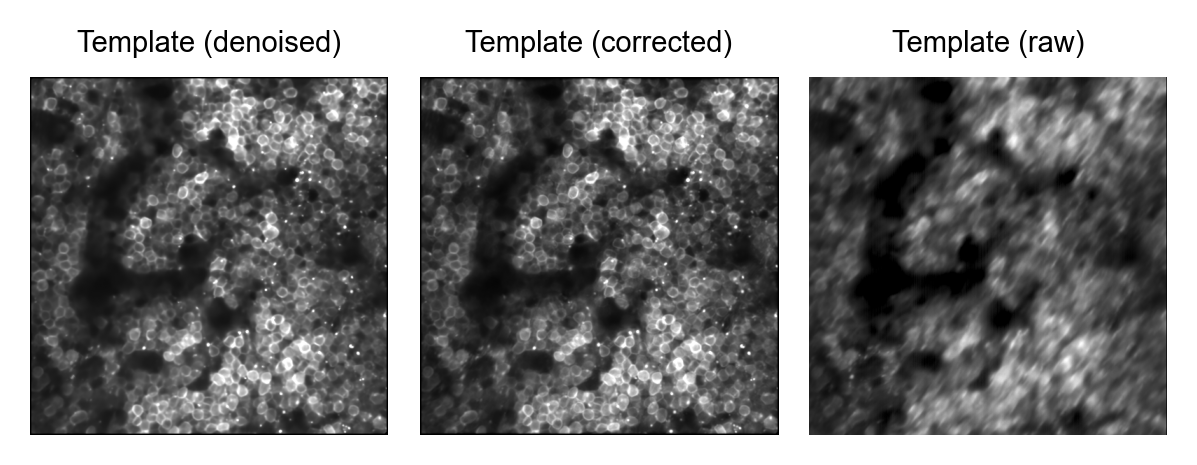

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(4,1.5), dpi=300)
axs[0].imshow(template_denoised, vmin=10, vmax=2200, cmap="gray")
axs[0].set_title("Template (denoised)")
axs[1].imshow(template_corrected, vmin=10, vmax=2200, cmap="gray")
axs[1].set_title("Template (corrected)")
axs[2].imshow(template_raw, vmin=10, vmax=2200, cmap="gray")
axs[2].set_title("Template (raw)")
for i in range(3):
    axs[i].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "templates.pdf"), bbox_inches="tight")
plt.show()

### Plot drift trace

In [10]:
rigid_shifts = np.load(os.path.join(rootdir, "mcorr_rigid", "shifts_rig.npy"))
x_shifts = np.load(os.path.join(rootdir, "mcorr_nonrigid", "y_shifts_els.npy"))
y_shifts = np.load(os.path.join(rootdir, "mcorr_nonrigid", "x_shifts_els.npy"))

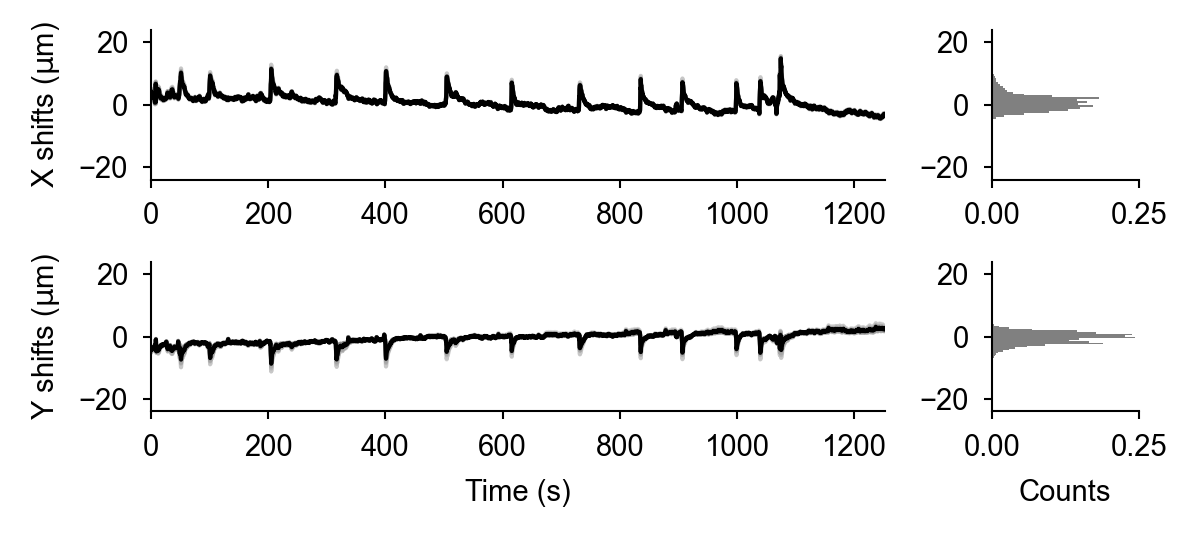

X shift: Mean = 0.6725707070707072, STD = 2.457240348888545
Y shift: Mean = -0.4817247474747476, STD = 1.8023652805052386


In [ ]:
fig = plt.figure(figsize=(4,1.8), dpi=300)
gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.2])

# 1 pixel = 0.52 um
xs = (rigid_shifts[30:-30, 0] + x_shifts.T).T * 0.52
ys = (rigid_shifts[30:-30, 1] + y_shifts.T).T * 0.52
xs = xs[::5]
ys = ys[::5]
t = 1/15.4 * 5 * np.arange(xs.shape[0])

for i in range(2):
    if i == 0:
        s = xs
    else:
        s = ys
    ax = fig.add_subplot(gs[i, 0])
    for jj in range(x_shifts.shape[1]):
        ax.plot(t, s[:, jj], color="gray", alpha=0.25, lw=1)
    ax.plot(t, s.mean(axis=1), color="k", lw=1)
    if i == 0:
        ax.set_ylabel('X shifts ($\mathrm{\mu}$m)')
        # ax.set_xticks([])
    else:
        ax.set_ylabel('Y shifts ($\mathrm{\mu}$m)')
        ax.set_xlabel("Time (s)")
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim([-24,24])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

for i in range(2):
    if i == 0:
        s = xs
    else:
        s = ys
    ax = fig.add_subplot(gs[i, 1])
    h, bin_edges = np.histogram(s.ravel(), bins=32, density=True)
    bins = (bin_edges[:-1] + bin_edges[1:])/2
    ax.barh(bins, h, height=bin_edges[:-1]-bin_edges[1:], color="gray")
    ax.set_ylim([-24,24])
    # ax.set_yticks([])
    ax.set_xlim(0, 0.25)
    if i == 0:
        pass
    else:
        ax.set_xlabel("Counts")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "drift_trace.pdf"), bbox_inches="tight")
plt.show()

print(f"X shift: Mean = {xs.ravel().mean()}, STD = {xs.ravel().std()}")
print(f"Y shift: Mean = {ys.ravel().mean()}, STD = {ys.ravel().std()}")

### Correlation between the template and each frame

In [12]:
r1 = np.load(os.path.join(rootdir, "mcorr_nonrigid/QC/QC_denoised/correlations.npy"))
r2 = np.load(os.path.join(rootdir, "mcorr_nonrigid/QC/QC_nonrigid/correlations.npy"))
r3 = np.load(os.path.join(rootdir, "mcorr_nonrigid/QC/QC_raw/correlations.npy"))

In [13]:
r1 = r1[::5]
r2 = r2[::5]
r3 = r3[::5]

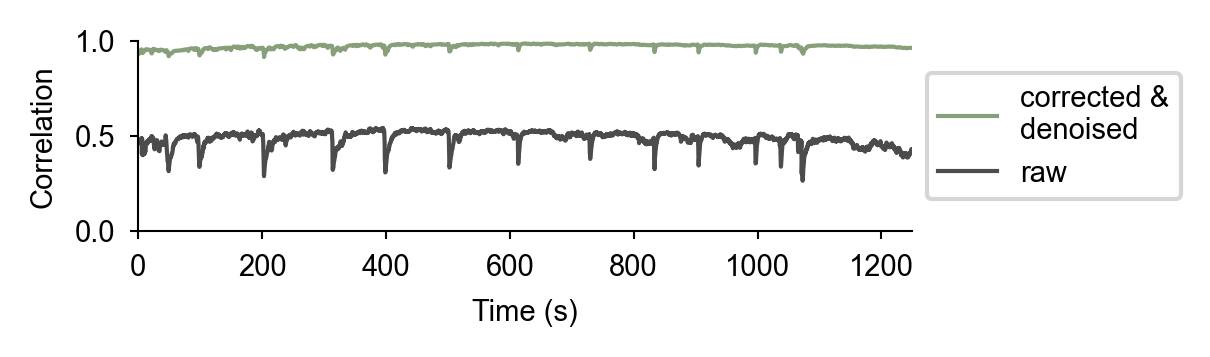

In [14]:
t = 1/15.4 * 5 * np.arange(r1.shape[0])

fig, ax = plt.subplots(figsize=(4.1,1.2), dpi=300)
ax.plot(t, r1, lw=1, label="corrected &\ndenoised", color="#88A07A")
# ax.plot(t, r2[30:-30], lw=1, label="corrected", color="#6C8EBF")
# ax.plot(t, r3[60:-60], lw=1, label="raw",  color="#4C4C4C")
ax.plot(t, r3[12:-12], lw=1, label="raw",  color="#4C4C4C")

ax.set_ylabel('Correlation')
ax.set_xlabel("Time (s)")
ax.set_ylim([0, 1])
ax.set_xlim(t[0], t[-1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "correlation.pdf"), bbox_inches="tight")
plt.show()

### Save to bucket

In [15]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250420_calcium_method_suppl"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250420_calcium_method_suppl
cp -r /flash/ReiterU/tmp/tomo_LROGTEZFMROI/* /bucket/ReiterU/OLdev/analysis/20250420_calcium_method_suppl
